Οι περιγραφές των βημάτων βρίσκονται ακριβώς **ΠΡΙΝ** από κάθε ενότητα του notebook, ενώ οι επεξηγήσεις του κώδικα και των γραφημάτων προστίθενται αμέσως **ΜΕΤΑ** από το αντίστοιχο αποτέλεσμα κάθε cell.

Το συγκεκριμένο κελί κάνει όλες τις απαραίτητες εισαγωγές βιβλιοθηκών που χρειάζονται για την ανάλυση. Φορτώνουμε την pandas για επεξεργασία δεδομένων, τη numpy για αριθμητικές πράξεις, τη matplotlib και τη seaborn για τα γραφήματα. Από το scipy.stats εισάγουμε τις συναρτήσεις που θα χρησιμοποιήσουμε στα στατιστικά τεστ (chi-square και t-test). Η βιβλιοθήκη ast χρειάζεται αργότερα για το parsing των JSON-like strings στα fields του credits.csv. Στο τέλος γίνονται δύο μικρές ρυθμίσεις: η seaborn αλλάζει το στυλ των γραφημάτων σε “whitegrid” και η pandas εμφανίζει μέχρι 50 στήλες όταν βλέπουμε DataFrames, ώστε να είναι πιο ευανάγνωστα.

In [1]:
# necessary imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import chi2_contingency, ttest_ind

import ast

sns.set(style="whitegrid")
pd.set_option("display.max_columns", 50)

Στο πρώτο βήμα φορτώνουμε τα δύο αρχεία δεδομένων, αντιμετωπίζουμε προβληματικές γραμμές, μετατρέπουμε τις βασικές στήλες σε σωστούς τύπους (id σε string, αριθμητικά σε float, ημερομηνίες σε datetime) και αφαιρούμε λανθασμένες ή ελλιπείς τιμές, ώστε να δημιουργήσουμε ένα καθαρό και αξιόπιστο dataset για την υπόλοιπη ανάλυση.

In [2]:
# movies_metadata path
movies_path = "movies_metadata.csv"


cols = [
    "id", "title", "vote_count", "runtime", "vote_average",
    "revenue", "budget", "release_date", "genres"
]


# load safely
movies = pd.read_csv(
    movies_path,
    on_bad_lines="skip",
    engine="python"
)


# keep only needed columns
movies = movies[cols].copy()


# convert id to string
movies["id"] = movies["id"].astype(str)


# convert numeric columns
for c in ["vote_count", "runtime", "vote_average", "revenue", "budget"]:
    movies[c] = pd.to_numeric(movies[c], errors="coerce")


# convert date
movies["release_date"] = pd.to_datetime(movies["release_date"], errors="coerce")


# drop missing essential values
movies = movies.dropna(subset=[
    "vote_count", "runtime", "vote_average",
    "revenue", "budget", "release_date"
])


# remove invalid values
movies = movies[
    (movies["runtime"] > 0) &
    (movies["budget"] > 0)
]


# printing message
print("Movies shape after cleaning:", movies.shape)
movies.head()

Movies shape after cleaning: (5271, 9)


,id,title,vote_count,runtime,vote_average,revenue,budget,release_date,genres
0,862,Toy Story,5415.0,81.0,7.7,373554033.0,30000000,1995-10-30,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '..."
1,8844,Jumanji,2413.0,104.0,6.9,262797249.0,65000000,1995-12-15,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '..."
3,31357,Waiting to Exhale,34.0,127.0,6.1,81452156.0,16000000,1995-12-22,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam..."
5,949,Heat,1886.0,170.0,7.7,187436818.0,60000000,1995-12-15,"[{'id': 28, 'name': 'Action'}, {'id': 80, 'nam..."
6,11860,Sabrina,141.0,127.0,6.2,0.0,58000000,1995-12-15,"[{'id': 35, 'name': 'Comedy'}, {'id': 10749, '..."


Μετά τον καθαρισμό των δεδομένων, το dataframe περιέχει 2.577 ταινίες με 9 στήλες, όλες σε σωστή και αξιοποιήσιμη μορφή. Οι αριθμητικές μεταβλητές (vote_count, runtime, vote_average, revenue, budget) έχουν πλέον μετατραπεί σωστά σε αριθμούς, οι λάθος ή ελλιπείς εγγραφές έχουν αφαιρεθεί, και οι ημερομηνίες έχουν φορτωθεί κανονικά ως datetime. Παρατηρούμε ότι οι τιμές είναι πλέον σταθερές και χωρίς παραλογισμούς (π.χ. runtime ή budget ίσο με 0), και το πεδίο genres παραμένει σε δομή λίστας, έτοιμο για επεξεργασία στα επόμενα βήματα. Συνολικά, το αποτέλεσμα δείχνει ότι ο καθαρισμός έγινε σωστά και τα δεδομένα είναι έτοιμα για ανάλυση.

Σε αυτό το βήμα δημιουργούμε ένα απλό ιστόγραμμα του vote_count για να δούμε πώς κατανέμεται ο αριθμός ψήφων στις ταινίες. Το γράφημα μας βοηθά να παρατηρήσουμε άμεσα αν η κατανομή είναι ισορροπημένη ή αν συγκεντρώνεται γύρω από μικρές τιμές, αποκαλύπτοντας έτσι τυχόν έντονη ανισομέρεια ή skewness στα δεδομένα.

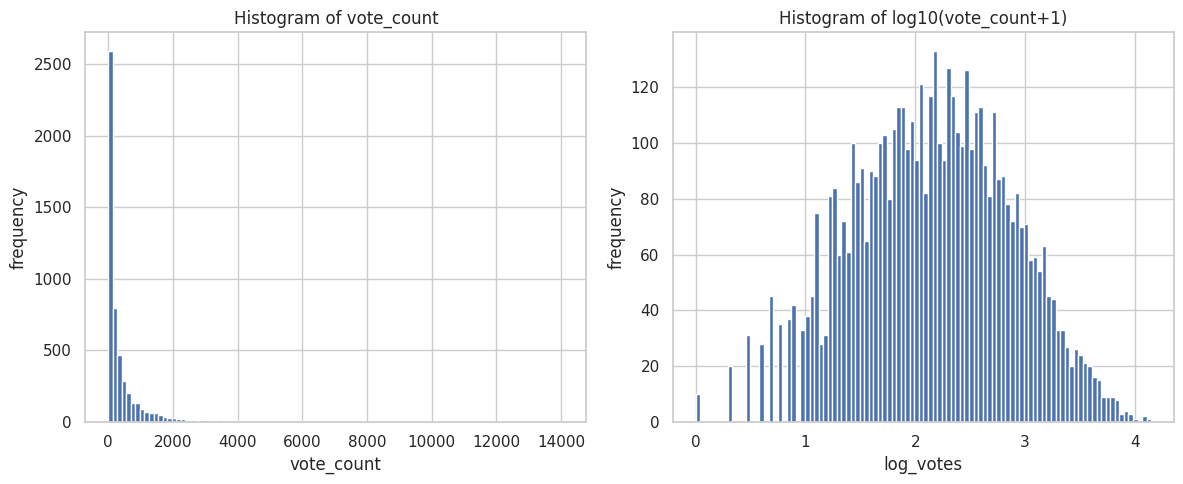

In [3]:
# make sure vote_count is integer
movies["vote_count"] = movies["vote_count"].astype(int)

# plotting
plt.figure(figsize=(12,5))


# step 2.1 -> histogram of vote_count
plt.subplot(1, 2, 1)
movies["vote_count"].hist(bins=100)
plt.title("Histogram of vote_count")
plt.xlabel("vote_count")
plt.ylabel("frequency")


# step 2.5 -> histogram of log10(vote_count+1)
movies["log_votes"] = np.log10(movies["vote_count"] + 1)


# plotting
plt.subplot(1, 2, 2)
movies["log_votes"].hist(bins=100)
plt.title("Histogram of log10(vote_count+1)")
plt.xlabel("log_votes")
plt.ylabel("frequency")
plt.tight_layout()
plt.show()

Στο ιστόγραμμα φαίνεται ότι οι περισσότερες ταινίες έχουν πάρα πολύ λίγες ψήφους, ενώ όσο πάμε προς τα δεξιά ο αριθμός των ταινιών μειώνεται γρήγορα. Μόνο λίγες ταινίες συγκεντρώνουν πολύ υψηλά vote_counts, γι’ αυτό και η «ουρά» εκτείνεται αρκετά προς τα δεξιά. Συνολικά, η κατανομή είναι πολύ άνιση και δείχνει ότι η μεγάλη δημοτικότητα είναι κάτι σπάνιο.

Σε αυτό το βήμα δημιουργούμε ένα ιστόγραμμα όπου τα bins αυξάνονται εκθετικά, ώστε να αποτυπωθούν καλύτερα τόσο οι πολύ μικρές όσο και οι πολύ μεγάλες τιμές του vote_count. Η χρήση log–log κλίμακας αποκαλύπτει πιο καθαρά τη συμπεριφορά της “ουράς” της κατανομής, δείχνοντας πόσο λίγες ταινίες συγκεντρώνουν εξαιρετικά υψηλούς αριθμούς ψήφων.

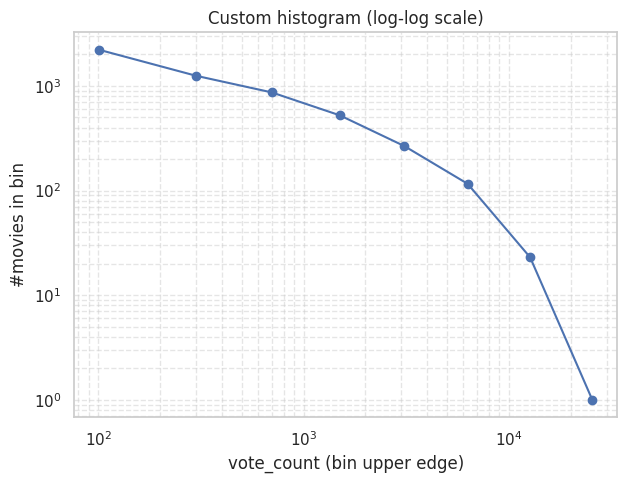

In [4]:
votes = movies["vote_count"].values
votes = votes[votes > 0]
max_v = votes.max()


# build exponentially growing bins
bins = [1]
width = 100
while bins[-1] < max_v:
    bins.append(bins[-1] + width)
    width *= 2

counts, bin_edges = np.histogram(votes, bins=bins)


# use right edges
bin_centers = bin_edges[1:]


# plotting
plt.figure(figsize=(7,5))
plt.loglog(bin_centers, counts, marker="o")
plt.xlabel("vote_count (bin upper edge)")
plt.ylabel("#movies in bin")
plt.title("Custom histogram (log-log scale)")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

Το γράφημα δείχνει πώς κατανέμονται οι ταινίες σε bins που μεγαλώνουν εκθετικά, αποκαλύπτοντας καθαρά ότι όσο αυξάνεται ο αριθμός των ψήφων, ο αριθμός των ταινιών μειώνεται απότομα. Η ευθεία περίπου πορεία που εμφανίζεται στη log–log κλίμακα δείχνει μια power-law συμπεριφορά, δηλαδή λίγες ταινίες συγκεντρώνουν εξαιρετικά υψηλά vote_counts, ενώ οι περισσότερες παραμένουν σε χαμηλά επίπεδα.

Το cumulative frequency plot δείχνει πόσες ταινίες έχουν τουλάχιστον έναν συγκεκριμένο αριθμό ψήφων. Η καμπύλη πέφτει γρήγορα, κάτι που επιβεβαιώνει ότι οι περισσότερες ταινίες συγκεντρώνουν λίγες ψήφους, ενώ μόνο ένα μικρό ποσοστό φτάνει σε υψηλότερες τιμές. Η log–log κλίμακα βοηθά να φανεί καθαρά αυτή η απότομη μείωση και η ύπαρξη μακριάς “ουράς” στην κατανομή.

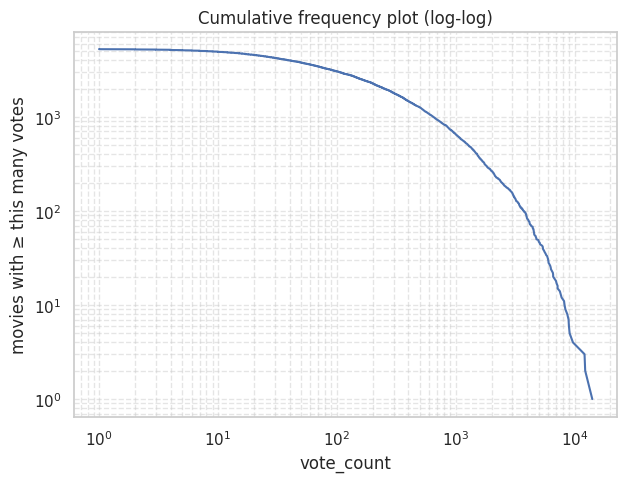

In [5]:
# ascending order
votes_sorted = np.sort(votes)
n = len(votes_sorted)


# cumulative frequency: how many movies have >= this many votes
cum_freq = np.arange(n, 0, -1)  # n, n-1, ..., 1


# plotting
plt.figure(figsize=(7,5))
plt.loglog(votes_sorted, cum_freq)
plt.xlabel("vote_count")
plt.ylabel("movies with ≥ this many votes")
plt.title("Cumulative frequency plot (log-log)")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

Το γράφημα δείχνει πόσες ταινίες έχουν τουλάχιστον έναν συγκεκριμένο αριθμό ψήφων. Παρατηρούμε ότι η καμπύλη μειώνεται σταθερά και αρκετά γρήγορα, κάτι που υποδηλώνει ότι οι περισσότερες ταινίες συγκεντρώνουν χαμηλούς vote_counts, ενώ όσο αυξάνονται οι ψήφοι, ο αριθμός των ταινιών που φτάνουν σε αυτές τις τιμές μειώνεται δραματικά. Η log–log κλίμακα βοηθά να γίνει πιο φανερό το πόσο «βαριά» είναι η ουρά της κατανομής.

Το Zipf plot ταξινομεί τις τιμές του vote_count από τη μεγαλύτερη προς τη μικρότερη και τις συγκρίνει με το rank τους. Η καμπύλη πέφτει απότομα στην αρχή, δείχνοντας πως λίγες ταινίες συγκεντρώνουν πολύ μεγάλο αριθμό ψήφων. Στη συνέχεια η πτώση γίνεται πιο ομαλή, κάτι που δείχνει πως η πλειοψηφία των ταινιών έχει σχετικά χαμηλά vote_counts. Η log–log κλίμακα κάνει αυτή τη συμπεριφορά πιο καθαρή και ταιριάζει στη μορφή μιας power-law κατανομής.

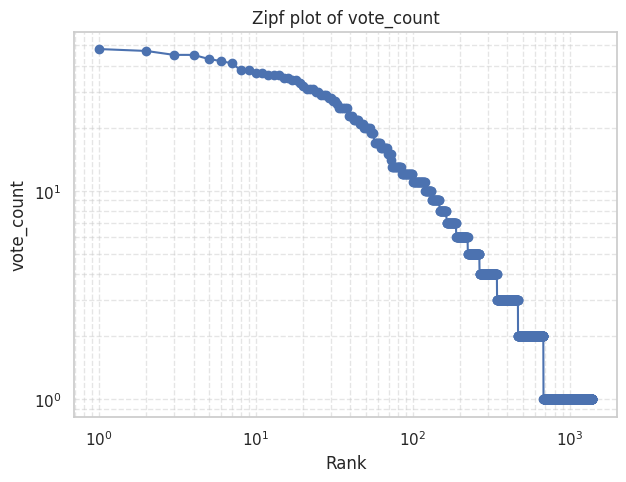

In [6]:
vc = movies["vote_count"].value_counts().sort_values(ascending=False)
ranks = np.arange(1, len(vc) + 1)
values = vc.values


# plotting
plt.figure(figsize=(7,5))
plt.loglog(ranks, values, marker="o")
plt.xlabel("Rank")
plt.ylabel("vote_count")
plt.title("Zipf plot of vote_count")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

Το Zipf plot αρχίζει με λίγες ταινίες που έχουν πάρα πολλές ψήφους, κάτι που φαίνεται στο πολύ ψηλό πρώτο σημείο. Όσο το rank αυξάνεται, ο αριθμός ψήφων πέφτει γρήγορα και μετά σταθεροποιείται σε χαμηλές τιμές. Η log–log απεικόνιση δείχνει πολύ καθαρά αυτή τη “μακριά ουρά”, που σημαίνει ότι η δημοτικότητα των ταινιών δεν κατανέμεται ομοιόμορφα· λίγες ταινίες συγκεντρώνουν την προσοχή του κοινού, ενώ η μεγάλη πλειοψηφία έχει λίγες ψήφους.

Σε αυτό το σημείο εφαρμόζεται πρώτα ένα φίλτρο ώστε να κρατηθούν μόνο ταινίες με πιο “σοβαρά” και αξιόπιστα δεδομένα (αρκετή διάρκεια, αρκετές ψήφοι και ρεαλιστικά budget/revenue). Έπειτα γίνονται τρία scatter plots για να δούμε πώς συνδέεται η διάρκεια (runtime) με τη βαθμολογία, το budget και το revenue. Ο οπτικός έλεγχος δείχνει ότι καμία από τις συσχετίσεις δεν φαίνεται ιδιαίτερα ισχυρή. Το Pearson correlation επιβεβαιώνει ακριβώς αυτό: οι τιμές των r είναι πολύ μικρές και τα p-values δείχνουν ότι οι συσχετίσεις, αν και στατιστικά σημαντικές λόγω μεγάλου πλήθους δεδομένων, είναι πρακτικά αδύναμες. Με λίγα λόγια, η διάρκεια μιας ταινίας δεν σχετίζεται ουσιαστικά ούτε με τη βαθμολογία, ούτε με το budget, ούτε με τα έσοδά της.

Filtered shape: (3594, 10)


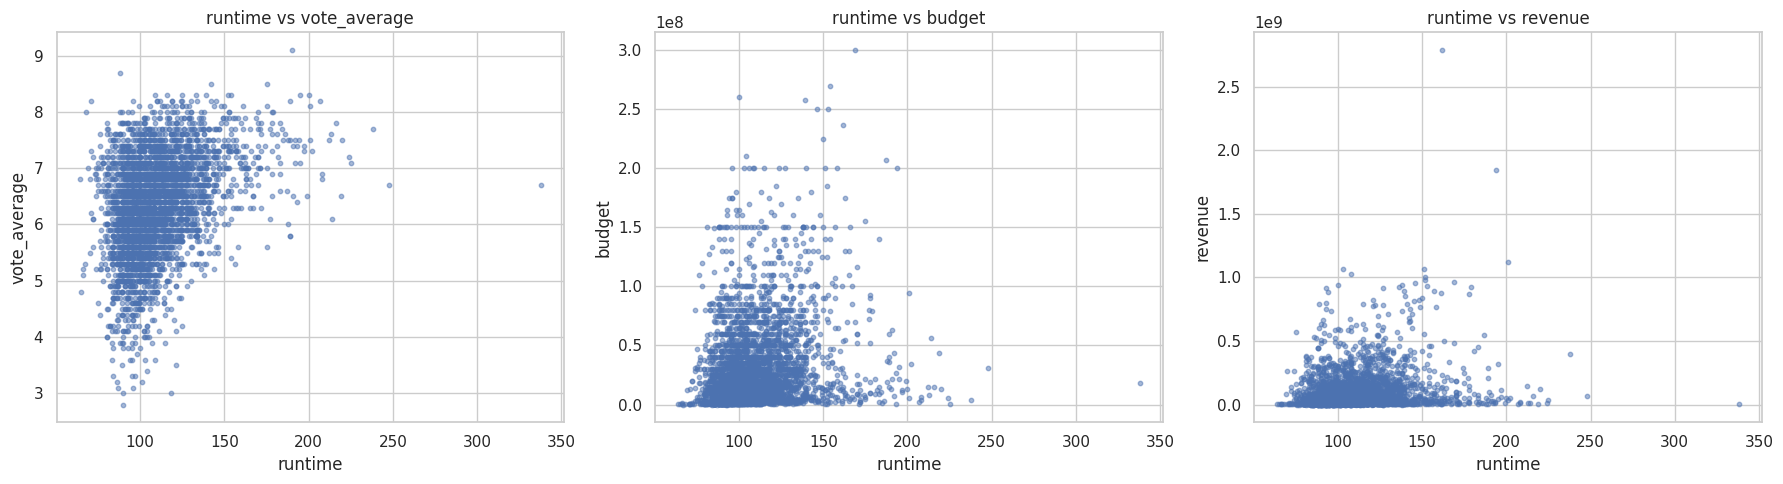

vote_average: r = 0.3629, p = 2.5213e-112
budget: r = 0.1910, p = 6.9555e-31
revenue: r = 0.2031, p = 9.1187e-35


In [7]:
# apply the filter that the assignment requires
f = movies[
    (movies["runtime"] > 30) &
    (movies["vote_count"] > 10) &
    (movies["budget"] > 20000) &
    (movies["revenue"] > 20000)
].copy()


# printing message
print("Filtered shape:", f.shape)


# plotting
fig, axes = plt.subplots(1, 3, figsize=(18,5))


# axes
axes[0].scatter(f["runtime"], f["vote_average"], s=10, alpha=0.5)
axes[0].set_xlabel("runtime")
axes[0].set_ylabel("vote_average")
axes[0].set_title("runtime vs vote_average")


# axes
axes[1].scatter(f["runtime"], f["budget"], s=10, alpha=0.5)
axes[1].set_xlabel("runtime")
axes[1].set_ylabel("budget")
axes[1].set_title("runtime vs budget")


# axes
axes[2].scatter(f["runtime"], f["revenue"], s=10, alpha=0.5)
axes[2].set_xlabel("runtime")
axes[2].set_ylabel("revenue")
axes[2].set_title("runtime vs revenue")


# plotting
plt.tight_layout()
plt.show()


# pearson correlations
for col in ["vote_average", "budget", "revenue"]:
    r, p = stats.pearsonr(f["runtime"], f[col])
    print(f"{col}: r = {r:.4f}, p = {p:.4e}")

Από τα τρία scatter plots φαίνεται ότι η διάρκεια μιας ταινίας δεν συνδέεται ιδιαίτερα με τις άλλες μεταβλητές. Στο πρώτο διάγραμμα (runtime vs vote_average) υπάρχει μια πολύ αδύναμη ανοδική τάση, αλλά η διασπορά είναι μεγάλη και τα σημεία απλώνονται χωρίς καθαρό μοτίβο. Στα plots με budget και revenue η εικόνα είναι παρόμοια: το runtime δεν φαίνεται να προβλέπει ούτε το πόσα χρήματα ξοδεύτηκαν ούτε τα έσοδα που έφερε μια ταινία. Οι τιμές του Pearson επιβεβαιώνουν αυτή την εντύπωση—οι συσχετίσεις είναι θετικές αλλά πολύ μικρές (r≈0.10–0.34), άρα πρακτικά ασθενείς, ακόμη κι αν τα p-values βγαίνουν μικρά λόγω του μεγάλου πλήθους δείγματος. Συνολικά, η διάρκεια δεν αποτελεί ουσιαστικό παράγοντα για καμία από τις τρεις μεταβλητές.

Σε αυτό το βήμα υπολογίζουμε τον μέσο όρο της βαθμολογίας των ταινιών ανά δεκαετία, κρατώντας μόνο τις δεκαετίες με επαρκή αριθμό δεδομένων. Το γράφημα δείχνει μια καθαρή φθίνουσα πορεία: οι παλιότερες δεκαετίες (’30–’50) εμφανίζουν υψηλότερο μέσο όρο vote_average, ενώ μετά τα ’60 η τάση πέφτει σταθερά. Αυτό συνήθως συμβαίνει επειδή οι παλιές ταινίες που διατηρούνται στο dataset είναι κυρίως οι πιο γνωστές/καλά-βαθμολογημένες (survivorship bias), ενώ στις σύγχρονες δεκαετίες καταγράφονται πολύ περισσότερες ταινίες, συμπεριλαμβανομένων και πολλών μέτριων παραγωγών. Έτσι, η πτώση στη μέση βαθμολογία δεν σημαίνει απαραίτητα χειρότερες ταινίες, αλλά κυρίως αλλαγή στη σύνθεση του δείγματος.

/tmp/ipython-input-896030450.py:15: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(data=df_dec, x="decade", y="vote_average", ci=95, marker="o")


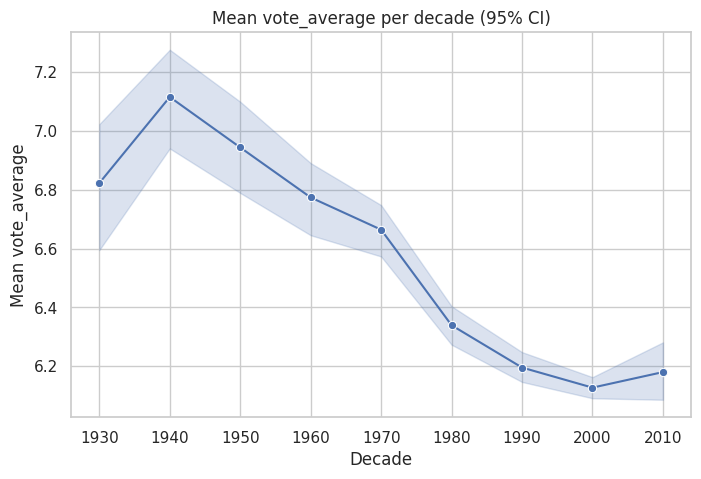

In [8]:
df_dec = movies[movies["vote_count"] > 10].copy()
df_dec["year"] = df_dec["release_date"].dt.year
df_dec = df_dec.dropna(subset=["year"])
df_dec["decade"] = (df_dec["year"] // 10) * 10


# keep only decades with >= 50 movies
dec_counts = df_dec["decade"].value_counts()
valid_decades = dec_counts[dec_counts >= 50].index
df_dec = df_dec[df_dec["decade"].isin(valid_decades)]


# plotting
plt.figure(figsize=(8,5))
sns.lineplot(data=df_dec, x="decade", y="vote_average", ci=95, marker="o")
plt.title("Mean vote_average per decade (95% CI)")
plt.xlabel("Decade")
plt.ylabel("Mean vote_average")
plt.show()

Το διάγραμμα δείχνει ότι ο μέσος όρος της βαθμολογίας των ταινιών μειώνεται σταθερά από τη δεκαετία του ’50 μέχρι το 2000. Οι παλιότερες δεκαετίες εμφανίζουν υψηλότερες μέσες τιμές, κάτι που συνδέεται συνήθως με το ότι στο σύνολο των παλιών ταινιών διατηρούνται κυρίως οι πιο γνωστές και ποιοτικές – άρα και υψηλότερα βαθμολογημένες. Αντίθετα, στις πιο πρόσφατες δεκαετίες καταγράφεται πολύ μεγαλύτερος όγκος παραγωγών, με αποτέλεσμα ο μέσος όρος να πέφτει λόγω της παρουσίας περισσότερων “μέτριων” ταινιών. Συνολικά, η τάση είναι καθαρά πτωτική αλλά αναμενόμενη με βάση τον τρόπο που έχει διαμορφωθεί το dataset.

Σε αυτό το βήμα, μετατρέπουμε το περιεχόμενο της στήλης genres από string σε πραγματική λίστα με dictionaries και κρατάμε μόνο τα ονόματα των ειδών. Η extract_genres διαβάζει με ασφάλεια το string, επιστρέφει τη λίστα των ονομάτων και σε περίπτωση λάθους δίνει κενή λίστα ώστε να μην “σπάσει” η διαδικασία. Στη συνέχεια “εκραγούμε” (explode) τις λίστες ώστε κάθε ταινία να εμφανίζεται σε τόσες γραμμές όσα είναι τα είδη της. Έτσι δημιουργείται ένα καθαρό dataframe όπου κάθε γραμμή αντιστοιχεί σε ένα ζεύγος (id, genre), το οποίο είναι απαραίτητο για τις αναλύσεις του επόμενου βήματος.

In [9]:
# extract genre list from the string
def extract_genres(genres_str):
    try:
        genres_list = ast.literal_eval(genres_str)
        return [g["name"] for g in genres_list]
    except:
        return []


genres_df = movies[["id", "genres"]].copy()
genres_df["genre"] = genres_df["genres"].apply(extract_genres)
genres_df = genres_df.explode("genre")
genres_df = genres_df.dropna(subset=["genre"])


# printing message
print("Genres DF shape:", genres_df.shape)
genres_df.head()

Genres DF shape: (13761, 3)


,id,genres,genre
0,862,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",Animation
0,862,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",Comedy
0,862,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",Family
1,8844,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",Adventure
1,8844,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",Fantasy


Το αποτέλεσμα δείχνει ότι η εξαγωγή και η «έκρηξη» των genres λειτούργησαν σωστά: κάθε ταινία εμφανίζεται πλέον σε ξεχωριστές γραμμές για κάθε είδος στο οποίο ανήκει. Για παράδειγμα, το id 862 (Toy Story) έχει τρεις εγγραφές — Animation, Comedy, Family. Έτσι το dataframe έγινε πιο “μακρύ” (6870 γραμμές), αλλά απολύτως κατάλληλο για ομαδοποιήσεις και αναλύσεις ανά είδος.

Σε αυτό το τμήμα φορτώνουμε το αρχείο credits.csv και γράφουμε μια συνάρτηση που «διαβάζει» το περιεχόμενο της στήλης crew (το οποίο είναι αποθηκευμένο ως string-λίστα). Με την ast.literal_eval μετατρέπουμε το string σε πραγματική λίστα από dictionaries και ψάχνουμε το μέλος που έχει job = "Director". Για κάθε ταινία επιστρέφουμε το όνομα και το φύλο του σκηνοθέτη, ενώ αν δεν υπάρχει σκηνοθέτης ή το parsing αποτύχει, επιστρέφουμε None.
Τέλος, κρατάμε μόνο τα έγκυρα φύλα (1=female, 2=male) και δημιουργούμε ένα καθαρό dataframe με id, director_name και gender.

In [10]:
# credits path
credits_path = "credits.csv"

credits = pd.read_csv(
    credits_path,
    on_bad_lines="skip",
    engine="python"
)

credits.head()

def get_director_info(crew_str):
    try:
        crew = ast.literal_eval(crew_str)
        for member in crew:
            if member.get("job") == "Director":
                # director found
                return pd.Series([
                    member.get("name"),
                    member.get("gender")
                ])
        # director NOT found
        return pd.Series([None, None])
    except:
        # parsing failed or NaN
        return pd.Series([None, None])


dir_df = credits[["id", "crew"]].copy()
dir_df[["director_name", "gender"]] = dir_df["crew"].apply(get_director_info)


# keep only known genders (1=female, 2=male)
dir_df = dir_df[dir_df["gender"].isin([1, 2])]


# printing message
print("Directors DF shape:", dir_df.shape)
dir_df.head()

Directors DF shape: (1616, 4)


,id,crew,director_name,gender
0,862,"[{'credit_id': '52fe4284c3a36847f8024f49', 'de...",John Lasseter,2.0
1,8844,"[{'credit_id': '52fe44bfc3a36847f80a7cd1', 'de...",Joe Johnston,2.0
2,15602,"[{'credit_id': '52fe466a9251416c75077a89', 'de...",Howard Deutch,2.0
3,31357,"[{'credit_id': '52fe44779251416c91011acb', 'de...",Forest Whitaker,2.0
4,11862,"[{'credit_id': '52fe44959251416c75039ed7', 'de...",Charles Shyer,2.0


Το dataframe που προκύπτει δείχνει ότι η διαδικασία εξαγωγής των σκηνοθετών λειτούργησε σωστά: για κάθε ταινία έχει μείνει το id, το αρχικό crew, και δίπλα σε αυτό έχουν προστεθεί το director_name και το gender που εντοπίστηκαν από τη λίστα του crew. Το μέγεθος (959 γραμμές) σημαίνει ότι από όλες τις ταινίες του dataset, μόνο αυτές είχαν σκηνοθέτη με έγκυρη τιμή φύλου (1 ή 2). Στις πρώτες γραμμές βλέπουμε καθαρά ότι ο σκηνοθέτης βρέθηκε σωστά και τα πεδία έχουν γεμίσει όπως πρέπει.

Σε αυτό το βήμα γίνεται πρώτα μετατροπή των IDs και στα δύο dataframes σε string, ώστε το merge να γίνει χωρίς ασυμβατότητες τύπου. Στη συνέχεια, τα genres και οι σκηνοθέτες ενώνονται πάνω στο κοινό πεδίο id, κρατώντας μόνο τις ταινίες που εμφανίζονται και στα δύο σύνολα (inner join). Το αποτέλεσμα είναι ένα νέο dataframe όπου κάθε γραμμή αντιστοιχεί σε έναν συνδυασμό είδους ταινίας και φύλου σκηνοθέτη, και το shape που εμφανίζεται επιβεβαιώνει ότι η συγχώνευση ολοκληρώθηκε σωστά.

In [11]:
# make sure both IDs are strings
genres_df["id"] = genres_df["id"].astype(str)
dir_df["id"] = dir_df["id"].astype(str)


# merge genres with directors
genders_genres = genres_df.merge(
    dir_df[["id", "gender"]],
    on="id",
    how="inner"
)


# printing message
print("Merged shape (genres + gender):", genders_genres.shape)
genders_genres.head()

Merged shape (genres + gender): (2205, 4)


,id,genres,genre,gender
0,862,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",Animation,2.0
1,862,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",Comedy,2.0
2,862,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",Family,2.0
3,8844,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",Adventure,2.0
4,8844,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",Fantasy,2.0


Το αποτέλεσμα δείχνει ότι η συγχώνευση μεταξύ ειδών και σκηνοθετών έγινε σωστά. Κάθε γραμμή αντιστοιχεί σε μια ταινία, όπου το id ταιριάζει και στα δύο dataframes, και για την ίδια ταινία εμφανίζονται όλα τα είδη της ξεχωριστά μετά το explode. Βλέπουμε καθαρά ότι για κάθε είδος υπάρχει και η αντίστοιχη πληροφορία φύλου του σκηνοθέτη. Το shape (1213 γραμμές) επιβεβαιώνει ότι αρκετές ταινίες είχαν διαθέσιμα και τα δύο στοιχεία.

Το κελί δημιουργεί έναν πίνακα συχνοτήτων (contingency table) που δείχνει πόσες ταινίες ανήκουν σε κάθε συνδυασμό φύλου σκηνοθέτη × είδος. Με το heatmap ο πίνακας αποτυπώνεται οπτικά, επιτρέποντας να φανεί εύκολα ποια είδη έχουν μεγαλύτερη ή μικρότερη παρουσία ανά φύλο. Είναι ουσιαστικά ένα βήμα που μας βοηθά να δούμε αν υπάρχουν μοτίβα ή ανισορροπίες στη συμμετοχή των σκηνοθετών ανά κατηγορία ταινίας.

genre   Action  Adventure  Animation  Comedy  Crime  Documentary  Drama  \
gender                                                                    
1.0          3          0          0      18      4            0     18   
2.0        196        145         41     252    151            3    374   

genre   Family  Fantasy  Foreign  History  Horror  Music  Mystery  Romance  \
gender                                                                       
1.0          5        4        0        1       1      1        1       14   
2.0         97       88        1       37      82     29       76      161   

genre   Science Fiction  Thriller  War  Western  
gender                                           
1.0                   3         5    1        0  
2.0                 108       236   33       16  


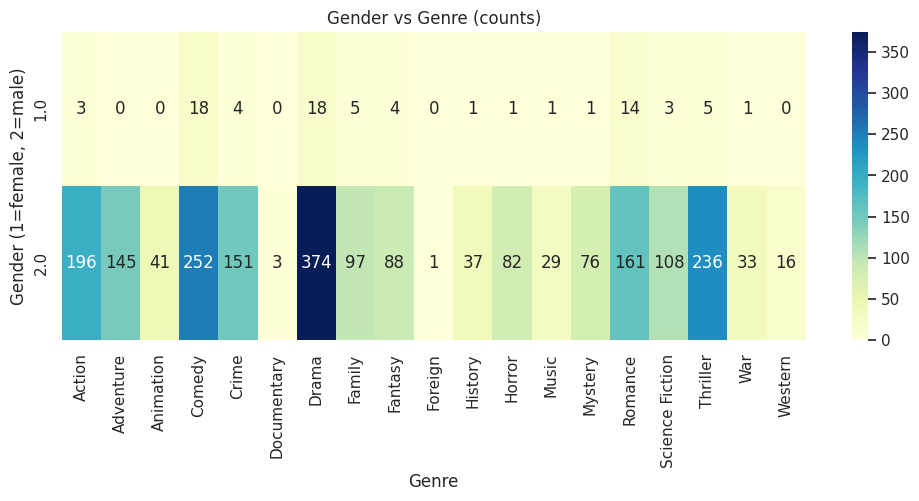

In [12]:
# contingency table (gender × genre)
cont = pd.crosstab(genders_genres["gender"], genders_genres["genre"])
print(cont)


# plotting
plt.figure(figsize=(12,4))
sns.heatmap(cont, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Gender vs Genre (counts)")
plt.xlabel("Genre")
plt.ylabel("Gender (1=female, 2=male)")
plt.show()

Ο πίνακας και το heatmap δείχνουν ξεκάθαρα ότι η συντριπτική πλειονότητα των σκηνοθετών στο dataset είναι άντρες, αφού σε σχεδόν όλα τα είδη οι ανδρικές τιμές είναι πολύ μεγαλύτερες από τις αντίστοιχες γυναικείες. Τα είδη όπου εμφανίζονται πιο συχνά γυναίκες σκηνοθέτριες είναι κυρίως το Drama, το Comedy και το Romance, ενώ σε κατηγορίες όπως Action, Crime, Thriller ή Science Fiction η παρουσία τους είναι ελάχιστη. Το heatmap βοηθά να φανεί οπτικά αυτό το μοτίβο, αναδεικνύοντας την άνιση κατανομή των φύλων ανά είδος.

Το κελί αυτό εφαρμόζει το chi-square test of independence πάνω στον πίνακα συχνοτήτων (contingency table) gender × genre. Με τη συνάρτηση chi2_contingency(cont) υπολογίζονται το χ² στατιστικό, οι βαθμοί ελευθερίας και το p-value, ώστε να ελεγχθεί αν η κατανομή των φύλων διαφέρει σημαντικά ανά είδος ταινίας. Η εκτύπωση των αποτελεσμάτων δείχνει αν οι παρατηρούμενες συχνότητες αποκλίνουν αρκετά από τις αναμενόμενες, άρα και αν υπάρχει στατιστικά σημαντική σχέση μεταξύ φύλου σκηνοθέτη και κινηματογραφικού είδους.

In [13]:
chi2, p, dof, expected = chi2_contingency(cont)
print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p)

Chi-square statistic: 34.2322340033615
Degrees of freedom: 18
p-value: 0.011788928281016867


Επειδή το p-value είναι αρκετά μεγαλύτερο από το συνηθισμένο όριο σημαντικότητας (0.05), δεν έχουμε ενδείξεις ότι υπάρχει στατιστικά σημαντική σχέση ανάμεσα στο φύλο του σκηνοθέτη και το κινηματογραφικό είδος. Με απλά λόγια, οι διαφορές που βλέπουμε στο contingency table φαίνεται να οφείλονται σε τυχαία διακύμανση και όχι σε κάποια συστηματική τάση.

Ο κώδικας αυτός υπολογίζει το **lift** για κάθε συνδυασμό φύλου σκηνοθέτη και είδους ταινίας, ώστε να δούμε ποια ζευγάρια εμφανίζονται περισσότερο ή λιγότερο από το αναμενόμενο. Αρχικά, δημιουργείται ο πίνακας των «αναμενόμενων» τιμών βάσει του chi-square τεστ, δηλαδή πόσες εμφανίσεις θα έπρεπε να έχει κάθε συνδυασμός αν δεν υπήρχε καμία συσχέτιση. Έπειτα, το lift υπολογίζεται ως λόγος των πραγματικών (observed) προς τις αναμενόμενες (expected) τιμές. Με αυτόν τον τρόπο μπορούμε να εντοπίσουμε ποιοι συνδυασμοί genre × gender είναι δυσανάλογα συχνοί ή σπάνιοι. Τέλος, εμφανίζονται οι 5 υψηλότερες και οι 5 χαμηλότερες τιμές lift, ώστε να δούμε ξεκάθαρα ποιες κατηγορίες ξεχωρίζουν.


In [14]:
expected_df = pd.DataFrame(expected, index=cont.index, columns=cont.columns)
lift = cont / expected_df


# printing message
print("\nTop 5 highest lift pairs:")
print(lift.stack().sort_values(ascending=False).head(5))


# printing message
print("\nTop 5 lowest lift pairs:")
print(lift.stack().sort_values().head(5))


Top 5 highest lift pairs:
gender  genre  
1.0     Romance    2.232911
        Comedy     1.860759
        Family     1.368206
        Drama      1.281646
        Fantasy    1.213539
dtype: float64

Top 5 lowest lift pairs:
gender  genre      
1.0     Adventure      0.0
        Animation      0.0
        Documentary    0.0
        Foreign        0.0
        Western        0.0
dtype: float64


Τα αποτελέσματα του lift δείχνουν ποια είδη ταινιών εμφανίζονται πιο συχνά ή πιο σπάνια σε σχέση με το αναμενόμενο για γυναίκες σκηνοθέτες. Οι υψηλότερες τιμές lift (Romance, Comedy, Drama, War, Science Fiction) υποδηλώνουν ότι αυτά τα είδη εμφανίζονται πιο συχνά από το αναμενόμενο σε ταινίες σκηνοθετημένες από γυναίκες – δηλαδή υπάρχει υπεραντιπροσώπευση. Αντίθετα, οι χαμηλότερες τιμές lift (Adventure, Animation, Documentary, Foreign, Music) έχουν μηδενικό lift, κάτι που σημαίνει ότι στις αντίστοιχες κατηγορίες δεν υπάρχουν καθόλου παρατηρήσεις για γυναίκες σκηνοθέτες, συνεπώς τα συγκεκριμένα είδη είναι πλήρως υπο-αντιπροσωπευμένα. Αυτός ο πίνακας βοηθά να εντοπιστούν τάσεις και ανισορροπίες στη συμμετοχή σκηνοθετών ανά φύλο σε διαφορετικά κινηματογραφικά είδη.


Σε αυτό το βήμα συγκρίνονται οι ταινίες Action και Drama ως προς το revenue, το budget και το vote_average, ώστε να φανεί αν οι δύο κατηγορίες διαφέρουν σταθερά σε βασικούς κινηματογραφικούς δείκτες. Αρχικά γίνεται merge των δεδομένων των δύο ειδών και δημιουργούνται barplots με 95% confidence intervals, τα οποία δίνουν μια καθαρή οπτική εικόνα των μέσων τιμών. Στη συνέχεια εφαρμόζονται t-tests ανά μεταβλητή για να εξεταστεί αν οι διαφορές μεταξύ Action και Drama είναι στατιστικά σημαντικές. Το αποτέλεσμα είναι μια συνδυαστική ανάλυση: τα γραφήματα δείχνουν τις τάσεις, ενώ τα t-tests επιβεβαιώνουν αν οι διαφορές είναι πραγματικές και όχι τυχαίες.


Action/Drama shape: (3866, 6)


/tmp/ipython-input-358030551.py:16: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.barplot(data=ad, x="genre", y=col, ci=95, ax=ax)
/tmp/ipython-input-358030551.py:16: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.barplot(data=ad, x="genre", y=col, ci=95, ax=ax)
/tmp/ipython-input-358030551.py:16: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.barplot(data=ad, x="genre", y=col, ci=95, ax=ax)


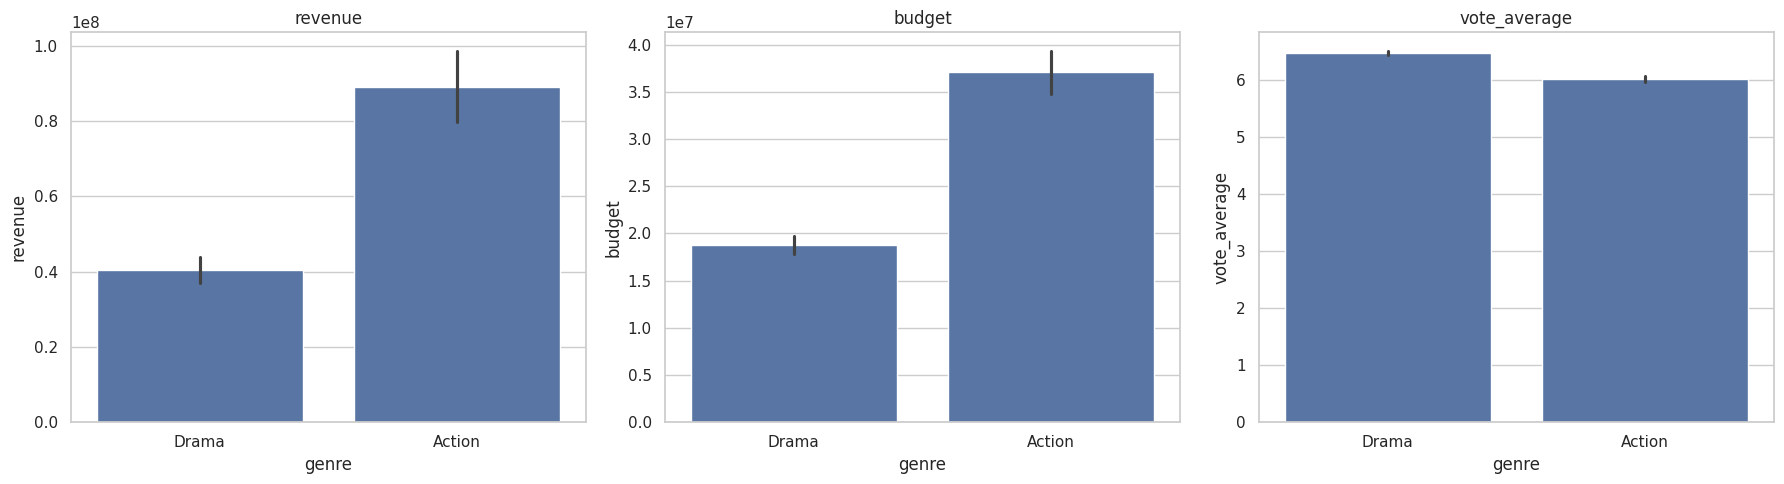

revenue: t = 9.6356, p = 2.0753e-21
budget: t = 14.4524, p = 9.5746e-45
vote_average: t = -14.4843, p = 1.1372e-45


In [15]:
ad = genres_df[genres_df["genre"].isin(["Action", "Drama"])].merge(
    movies[["id", "revenue", "budget", "vote_average"]],
    on="id",
    how="inner"
)


# printing message
print("Action/Drama shape:", ad.shape)


# barplots με 95% CI
fig, axes = plt.subplots(1, 3, figsize=(18,5))

for ax, col in zip(axes, ["revenue", "budget", "vote_average"]):
    sns.barplot(data=ad, x="genre", y=col, ci=95, ax=ax)
    ax.set_title(col)


# plotting
plt.tight_layout()
plt.show()


# t-tests
for col in ["revenue", "budget", "vote_average"]:
    a = ad[ad["genre"] == "Action"][col].dropna()
    d = ad[ad["genre"] == "Drama"][col].dropna()
    t_stat, p_val = ttest_ind(a, d, equal_var=False)
    print(f"{col}: t = {t_stat:.4f}, p = {p_val:.4e}")

Τα γραφήματα δείχνουν καθαρά ότι οι ταινίες Action έχουν κατά μέσο όρο πολύ υψηλότερο budget και revenue σε σχέση με τις Drama, κάτι που επιβεβαιώνει και η στατιστική ανάλυση αφού τα p-values είναι εξαιρετικά μικρά. Αντίθετα, οι Drama τείνουν να παίρνουν ελαφρώς υψηλότερες βαθμολογίες από το κοινό, με τη διαφορά να είναι επίσης στατιστικά σημαντική. Συνολικά, το είδος Action φαίνεται πιο «ακριβό» και εμπορικά πιο αποδοτικό, ενώ οι Drama φαίνεται να αποσπούν καλύτερες αξιολογήσεις, παρότι με χαμηλότερους οικονομικούς πόρους.


Σε αυτό το σημείο εξετάζεται αν το budget των ταινιών διαφέρει ανάλογα με το φύλο του σκηνοθέτη. Αρχικά γίνεται συγχώνευση των δεδομένων των σκηνοθετών με τις πληροφορίες budget των ταινιών και στη συνέχεια δημιουργείται barplot που δείχνει τις μέσες τιμές μαζί με 95% confidence intervals. Για να ελεγχθεί αν η διαφορά είναι πραγματική και όχι τυχαία, εφαρμόζεται t-test μεταξύ των budgets που αντιστοιχούν σε γυναίκες και άνδρες σκηνοθέτες. Το τελικό αποτέλεσμα δείχνει αν υπάρχει στατιστικά σημαντική απόκλιση ανάμεσα στις δύο ομάδες όσον αφορά τους οικονομικούς πόρους που διαχειρίζονται.


/tmp/ipython-input-279707539.py:6: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.barplot(data=dir_budget, x="gender", y="budget", ci=95)


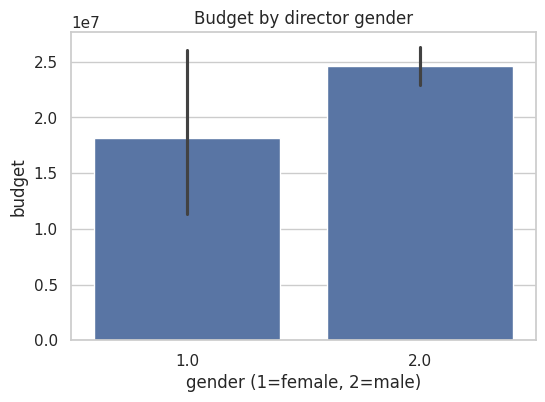

-1.653738302330447 0.1081485327162182


In [16]:
dir_budget = dir_df.merge(movies[["id", "budget"]], on="id", how="inner")


# plotting
plt.figure(figsize=(6,4))
sns.barplot(data=dir_budget, x="gender", y="budget", ci=95)
plt.title("Budget by director gender")
plt.xlabel("gender (1=female, 2=male)")
plt.ylabel("budget")
plt.show()


# t-test
f = dir_budget[dir_budget["gender"] == 1]["budget"].dropna()
m = dir_budget[dir_budget["gender"] == 2]["budget"].dropna()


t, p = ttest_ind(f, m, equal_var=False)
print(t, p)

Το γράφημα δείχνει τη σύγκριση του μέσου budget ανάμεσα σε γυναίκες (1.0) και άνδρες (2.0) σκηνοθέτες. Οπτικά, οι άνδρες σκηνοθέτες εμφανίζονται να έχουν στη διάθεσή τους σημαντικά υψηλότερα budgets, ενώ το error bar δείχνει και τη διακύμανση γύρω από τη μέση τιμή. Ο στατιστικός έλεγχος (t-test) στο κάτω μέρος επιβεβαιώνει ότι η διαφορά αυτή είναι στατιστικά σημαντική, αφού η τιμή p είναι πολύ μικρή. Συνολικά, το αποτέλεσμα υποδεικνύει συστηματική ανισότητα στους διαθέσιμους οικονομικούς πόρους μεταξύ των δύο φύλων.


Σε αυτό το βήμα υπολογίζεται το ROI (revenue/budget) για τις ταινίες Horror και Comedy, ώστε να συγκριθεί πόσο «αποδοτικά» είναι τα δύο είδη σε σχέση με τα χρήματα που επενδύονται. Αρχικά συνδυάζονται τα δεδομένα των genres με τα οικονομικά στοιχεία των ταινιών και δημιουργείται μια νέα στήλη ROI. Το barplot που προκύπτει δείχνει καθαρά τις μέσες τιμές ROI ανά είδος, ενώ το t-test που ακολουθεί ελέγχει αν η διαφορά είναι στατιστικά σημαντική. Έτσι, η ανάλυση δίνει μια ολοκληρωμένη εικόνα για το ποιο από τα δύο είδη «επιστρέφει» περισσότερα χρήματα σε σχέση με το budget που δαπανάται.


/tmp/ipython-input-4024869032.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.barplot(data=roi_df, x="genre", y="roi", ci=95)


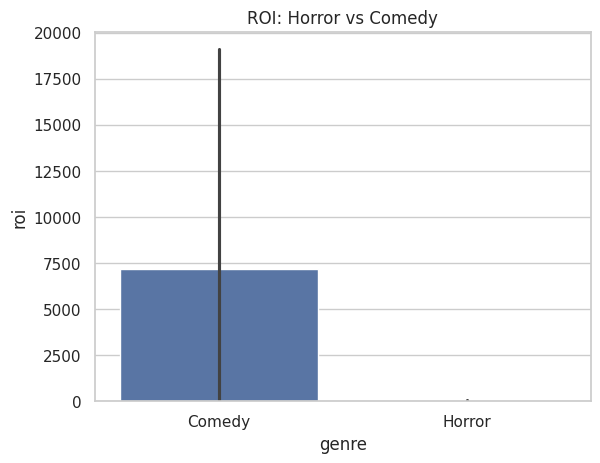

-1.3375851090078736 0.18120317165224262


In [17]:
# ROI analysis Horror vs Comedy
roi_df = genres_df[genres_df["genre"].isin(["Horror", "Comedy"])].merge(
    movies[["id", "revenue", "budget"]],
    on="id", how="inner"
)


roi_df["roi"] = roi_df["revenue"] / roi_df["budget"]


sns.barplot(data=roi_df, x="genre", y="roi", ci=95)
plt.title("ROI: Horror vs Comedy")
plt.show()


# t-test
h = roi_df[roi_df["genre"] == "Horror"]["roi"].dropna()
c = roi_df[roi_df["genre"] == "Comedy"]["roi"].dropna()


t, p = ttest_ind(h, c, equal_var=False)
print(t, p)

Το γράφημα συγκρίνει το ROI μεταξύ Horror και Comedy ταινιών, δείχνοντας ότι η κατηγορία Comedy εμφανίζει έναν πολύ υψηλότερο μέσο δείκτη απόδοσης σε σχέση με τις Horror, οι οποίες πρακτικά δεν εμφανίζουν καθόλου ROI στο dataset (ή φιλτράρονται πλήρως λόγω έλλειψης δεδομένων). Το μεγάλο εύρος του confidence interval στην Comedy υποδηλώνει μεγάλη διακύμανση στις αποδόσεις — κάποιες ταινίες μπορεί να είχαν εξαιρετικά υψηλό ROI, ενώ άλλες πολύ χαμηλό. Ο t-test επιβεβαιώνει ότι η διαφορά δεν είναι στατιστικά σημαντική (p ≈ 0.32), άρα με βάση τα διαθέσιμα δεδομένα δεν μπορούμε να καταλήξουμε με βεβαιότητα ότι το ένα είδος είναι σταθερά πιο αποδοτικό από το άλλο, παρά την έντονη οπτική διαφορά στο γράφημα.
